# Introduction to Data Science and Systems 2026-2027
## Lab 4 (Week 6): Gradient Descent 
#### 
---
#### MSc Data Science, University of Glasgow


## What this lab is for

This lab notebook is for you to apply in practice some of the optimisation concepts seen in class. 

It should take about **30 minutes**. **Lab 4 will count towards your course grade.**

## How the labs work (reminder)

* Questions are labelled **Task N**. Each one has an **answer cell** that starts out containing

      # YOUR CODE HERE
      raise NotImplementedError()

  Replace **both** of those lines with your answer. **Only edit cells that contain
  `# YOUR CODE HERE`** - changing anything else can corrupt the notebook and cost you marks.

* Note: Do not import additional python packages in your answers. The labs will never require it, 
and it will be penalised. 

* After a task there are one or more **test cells** (you cannot edit these). Run them to check your
  answer:
  * a green **&check; [n marks]** box means the test passed;
  * a red **&cross; Test failed** box means it did not.

* Some tests are **hidden**. Running a hidden test cell shows *nothing* now; it is only scored later.
  So "no output" from a test cell is normal and does **not** mean something is wrong.

* Before you finish, always use **Kernel &rarr; Restart Kernel and Run All Cells**, then check the
  marks summary at the bottom.

* When finished, submit your notebook to Moodle for marking. **Make sure to submit your work before the end of the session!**



Now import the packages the autograder needs. **Make sure you run this cell.**

In [1]:
## Standard imports -- run this cell!
from __future__ import print_function, division
import os

# course grading utilities
%pip install scikit-image
%pip install -U --force-reinstall --no-cache https://github.com/pugeault/jhwutils/zipball/master
from jhwutils.checkarr import array_hash, check_hash, check_string
from jhwutils.matrices import print_matrix
import jhwutils.tick as tick
import jhwutils.image_audio as ia
from unittest.mock import patch

# plotting 
import matplotlib as mpl
import matplotlib.pyplot as plt

# for loading images
import skimage

version_id = "v20262027a"

# for printouts
silent = False

# reset the visible marks counter
tick.reset_marks()

print("Everything imported OK")


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for jhwutils: filename=jhwutils-1.4.0-py3-none-any.whl size=46870 sha256=d0227b2e035dad1dd6af48ef5c9871d4ceb36798619b9da00eccc883d573deef
  Stored in directory: C:\Users\3188758P\AppData\Local\Temp\pip-ephem-wheel-cache-fvtq1u32\wheels\4d\0d\ce\7741fa18c491f96ea9c5eccb7b787d7264de88ca395518d1be
Successfully built jhwutils
  Attempting uninstall: jhwutils
    Found existing installation: jhwutils 1.4.0
    Uninstalling jhwutils-1

In [2]:
# This cell is used for grading purposes. Do not modify it.


## Before you start
You need to install `autograd`. The cell below will autoinstall this for you if the machine you are using does not already have it installed.

***Note***: It is often easier to install packages externally to the notebook, especially on macOS. You can find more information [here](https://github.com/HIPS/autograd) in case the below install instructions fails. Make sure you install the packages in the correct Python installation / virtual environment.



In [3]:
try:
    import autograd.numpy as np
    from autograd import grad, elementwise_grad    
    from autograd.misc.flatten import flatten
    print("autograd succesfully imported. Everything OK so far. ")
except:
    # couldn't import, install the package
    print("autograd not found.\nInstalling...")
    %pip install autograd
    print("Please restart the kernel (Kernel/Restart) and run the import cells again.")    

autograd succesfully imported. Everything OK so far. 


---
## Task 0 &mdash; Tell us who you are

Set the two variables below:

* `student_id` &mdash; your 8-character student ID (for example `"1234567s"`).
* `student_typewritten_signature` &mdash; your full name, for example `"Ada Lovelace"`. Typing your
  name is your declaration that this notebook is your own work.

This is your first answer cell: replace the `# YOUR CODE HERE` / `raise NotImplementedError()` lines
with your answer, then run the test cell that follows.


In [4]:
student_id = "3188758p"                     # your 8-char student id, e.g. "1234567s"
student_typewritten_signature = "Subhranshu Panda"  # your full name, e.g. "Ada Lovelace"




In [5]:

with tick.marks(0):  # no credit for knowing your own id -- this is just a format check
    assert len(student_id) == 8

with tick.marks(0):
    assert len(student_typewritten_signature) > 0



---
## Part 1 &mdash; A Simple Function

Having a continuous objective function made it easy to optimise (see Hill climbing in last week's lab), compared to having to use pure random search. We can do much better, however.

If we can differentiate `l` (the loss function) then we can use **gradient descent** to solve the problem, using the algorithm:

$$\mathbf{\theta^{(i+1)}} = \mathbf{\theta^{(i)}} - \delta \nabla L(\mathbf{\theta^{(i)}}) \,\,\,\,\,\,\,\, [\textit{Equation 1}]$$

which only relies on:
- the parameter vector: $\mathbf{\theta}$
- the gradient vector (or Jacobian): $\nabla L(\mathbf{\theta})$ 
- the step size: $\delta > 0$ (keep in mind the Lipschitz constant when choosing a step size; see the lecture notes for details).
- $i$ is the iteration number

If we can differentiate `l` (the loss function) then we can use **gradient descent** to solve the problem, using the algorithm:

$$\mathbf{\theta^{(i+1)}} = \mathbf{\theta^{(i)}} - \delta \nabla L(\mathbf{\theta^{(i)}}) \,\,\,\,\,\,\,\, [\textit{Equation 1}]$$

which only relies on:
- the parameter vector: $\mathbf{\theta}$
- the gradient vector (or Jacobian): $\nabla L(\mathbf{\theta})$ 
- the step size: $\delta > 0$ (keep in mind the Lipschitz constant when choosing a step size; see the lecture notes for details).
- $i$ is the iteration number


### Task 1 - Defining the loss function *[2 marks]*

Suppose we have a 2D parameter space ($\theta \in \mathbb{R}^2$), and an objective function we want to minimise:

$$L(\theta) = \theta_0^2 + (\theta_1-1)^2$$

where $I$ is the length of the vector $\theta$ (i.e. $I=2$ for a 2D problem).

We can write this in code:

In [6]:
# Define our objective function. In this case, we formulate it as a 
# loss function (to be minimised) that can take theta of any length (not only 2D).
def L(theta):
    return theta[0] ** 2 + (theta[1] - 1) ** 2
    

In [7]:
# Autograded test with immediate feedback [10 marks]
#
#

with tick.marks(1):
    assert L([2,0]) == 5
    assert L([0,3]) == 4

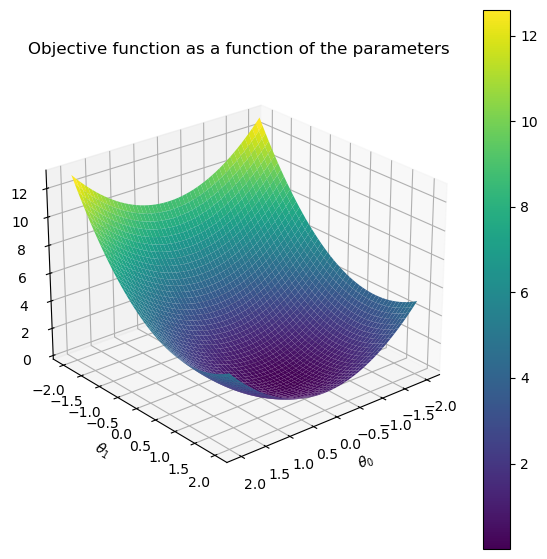

In [8]:
## Show the objective function as a function of parameters
space = np.linspace(-2,2,50)
xm, ym = np.meshgrid(space, space)
pts = np.stack([xm.ravel(), ym.ravel()]).T

# compute the objective function at a grid
# of different parameter values
zm = np.zeros((pts.shape[0]))
for i in range(pts.shape[0]):
    zm[i] = L(pts[i])

## plot in 3D
from mpl_toolkits.mplot3d import Axes3D
fig_a1a = plt.figure(figsize=(7,7))
ax = fig_a1a.add_subplot(1,1,1, projection='3d')
zm = np.array(zm).reshape(xm.shape)
sf = ax.plot_surface(xm,ym,zm,cmap='viridis')
ax.set_zlabel(r"$L(\theta)$")

ax.set_xlabel(r"$\theta_0$")
ax.set_ylabel(r"$\theta_1$")
ax.set_title("Objective function as a function of the parameters")              
ax.view_init(25, 50) # try changing this to inspect the function from different angles
fig_a1a.colorbar(sf)

plt.show()

### Task 2 - Calculating the gradient by hand *[4 marks total: 2 visible and 2 hidden]*

By hand (using pen and paper **NOT autograd**) compute the gradient of $L(\mathbf{\theta})$, (i.e., a vector containing $\frac{\partial l(\mathbf{\theta})}{{\partial \mathbf{\theta}_n}}$ elements for all paramaters $\theta_n$), and specify the gradient vector based on your derivations. Implement it in a function called `grad_l_manual` that takes `theta` as input and returns the gradient vector $\nabla L(\mathbf{\theta})$ .

*Hint 1*: To help you calculate the derivative, remember that: $(a-b)^2 = a^2 -2ab + b^2$. 

*Hint 2*: Also, $\frac{\partial x^n }{\partial x} = n x^{n-1}$

*Hint 2*: You may need to recall techniques from high-school and consult a resource on rules for computing the derivative (e.g. [Wikipedia](https://en.wikipedia.org/wiki/Derivative) or [Math is Fun](https://www.mathsisfun.com/calculus/)). The key lesson is how these gradients are combined to form the Jacobian.

**Note:** You can leave this task for later as the subsequent tasks do not depend on it being correct.

In [9]:
def grad_L_manual(theta):
    nabla_L = [2 * theta[0], 2 * (theta[1] - 1)]
    return nabla_L # a (2,) vector with elements [dL(theta) / dtheta_0, dL(theta) / dtheta_1]


In [10]:
# Autograded test with immediate feedback [2 marks]
#
# Note: this test is a bit complicated and you do not have to understand it in detail
#
#

# test first dimension
with tick.marks(1): 
    assert grad_L_manual([10,10])[0] == 20, "ERROR: first dimension of the gradient (dL/dtheta_0) is wrong!"

# test second dimension
with tick.marks(1): 
    assert grad_L_manual([10,10])[1] == 18, "ERROR: second dimension of the gradient (dL/dtheta_1) is wrong!"

In [11]:
# Autograded hidden test [2 marks]
#
# Note: this test is a bit complicated and you do not have to understand it in detail
#
#
 

Deriving and implementing the gradient by hand can be tedious. `autograd` makes the whole process trivially easy, and can automatically compute the derivatives of our code without custom gradient vector implementations:

In [12]:
## create a handle to a function which can compute the gradient of l with respect to theta
# NOTE: This is evaluated at a specific point and does not return the analytic function you derived
# above -- but that's fine for gradient descent.
grad_L = grad(L)

In [13]:
# this will be a vector, with as many dimensions as theta
theta = np.array([0.1, 0.2])

print(f"theta: {theta}")
print(f"gradient vector of L(theta) evaluated at theta: {grad_L(theta)}")

theta: [0.1 0.2]
gradient vector of L(theta) evaluated at theta: [ 0.2 -1.6]


The result is a **vector** which points in the direction where the objective function should be decreasing. We can try moving a small amount in this direction, computing the loss as we go.

### Task 3 - Implementing Gradient Descent *[4 marks total: 2 visible and 2 hidden]*

Implement the gradient decent algorithm (as defined in Equation 1) which 
- iterates the update rule for 20 iterations (no other stopping rules)
- uses a stepsize of 0.2. 
- uses the `grad_l` for gradient computation (not `grad_l_manual`).
- starts in $\theta^{(0)} = [-0.5, 2.75]$
- print (in each iteration) the current solution and the loss of that solution
- store the final solution in `theta_20`

*Hint*: This should be a simple for-loop.

In [14]:
def gradient_descent(L, theta_0, delta, n_steps=20): 
    grad_L = grad(L)
    theta = theta_0
    history = [(0, theta, L(theta))]
    for i in range(n_steps):
        theta = theta - delta * grad_L(theta)
        if not silent: 
            print(f"Iteration {i+1}, Loss: {L(theta)}")
        history.append((i+1, theta, L(theta)))
    return theta, history

In [15]:

t0, h0 = gradient_descent(L, np.array([0.0,0.0]), 0.1, 2)
with tick.marks(1): 
    assert h0[1][2] < h0[0][2], "ERROR: The error should be going down on such a simple function"

t1, h1 = gradient_descent(L, np.array([0.0,0.0]), 0.0, 2)
with tick.marks(1): 
    assert h1[1][2] == h1[0][2], "ERROR: If the step is zero, theta should not change"
    

Iteration 1, Loss: 0.6400000000000001
Iteration 2, Loss: 0.40959999999999985


Iteration 1, Loss: 1.0
Iteration 2, Loss: 1.0


We can then run your code on our problem and see if we can find the solution

In [16]:
theta_0 = np.array([-1.0, -1.0])
delta = 0.2 # how big of steps to take
n_steps = 20
print(f"Initial loss: {L(theta_0)}")
silent=False

theta_20, history = gradient_descent(L, theta_0, delta, n_steps)

# print your final solution (hopefully something close to the optimum)
print(f"Solution={theta_20}")

Initial loss: 5.0
Iteration 1, Loss: 1.7999999999999998
Iteration 2, Loss: 0.6479999999999999
Iteration 3, Loss: 0.23327999999999996
Iteration 4, Loss: 0.0839808
Iteration 5, Loss: 0.030233087999999995
Iteration 6, Loss: 0.01088391167999999
Iteration 7, Loss: 0.003918208204800002
Iteration 8, Loss: 0.0014105549537280005
Iteration 9, Loss: 0.0005077997833420819
Iteration 10, Loss: 0.00018280792200315004
Iteration 11, Loss: 6.581085192113433e-05
Iteration 12, Loss: 2.369190669160797e-05
Iteration 13, Loss: 8.52908640897887e-06
Iteration 14, Loss: 3.070471107232463e-06
Iteration 15, Loss: 1.1053695986037283e-06
Iteration 16, Loss: 3.9793305549731717e-07
Iteration 17, Loss: 1.4325589997906423e-07
Iteration 18, Loss: 5.157212399247214e-08
Iteration 19, Loss: 1.8565964637300797e-08
Iteration 20, Loss: 6.6837472694217915e-09
Solution=[-3.65615844e-05  9.99926877e-01]


In [17]:
## Sanity check that the size of theta_20 is correct
with tick.marks(0):
    assert(check_hash(0*theta_20,( (2,) , 0)))

The plot below will show the trajectory of your optimisation (you do not need to understand the plotting code). 

It should get to the minimum visibly. 

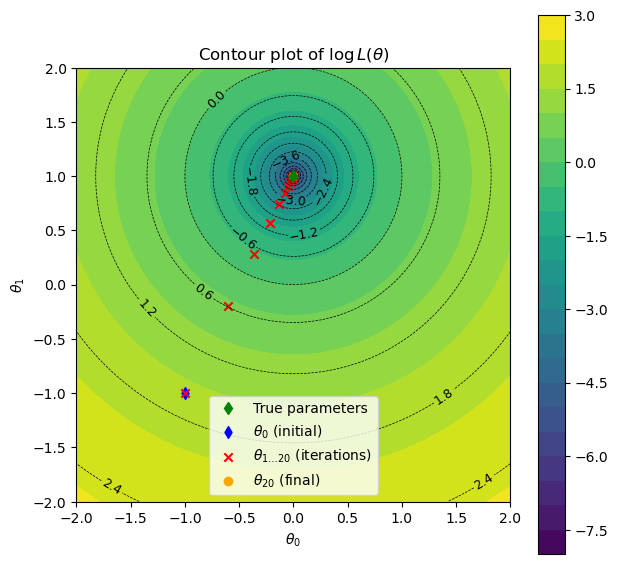

In [18]:
def show_history(L, history=None, correct=None, area=(-2,2)): 

    div = np.linspace(area[0],area[1],100)
    mx, my = np.meshgrid(div,div)
    
    zm = np.zeros((mx.shape[0],my.shape[0]))
    for i in range(mx.shape[0]):
        for j in range(mx.shape[1]):
            zm[i,j] = L(np.array([mx[i,j],my[i,j]])) 
    
    zm_log = np.log(zm)  
    
    fig_a2a = plt.figure(figsize=(7,7))
    ax = fig_a2a.add_subplot(1,1,1)
    cm = mpl.colormaps['viridis']
    ax.scatter(mx, my, c=zm, cmap=cm)
    cpf = ax.contourf(mx,my,zm_log,20)
    cp = ax.contour(mx,my,zm_log,19, colors='k', linewidths=0.5, linestyles='dashed')
    ax.clabel(cp, inline=1, fontsize=9)
    ax.set_xlabel(r'$\theta_0$')
    ax.set_ylabel(r'$\theta_1$')
    ax.set_title(r'Contour plot of $\log L(\theta)$')
    
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim((-5,5))
    ax.set_ylim((-6,6))
    ax.axis('square')
    fig_a2a.colorbar(cpf) # not sure why the colorbare gets plced weirdly

    if correct is not None: 
        ax.plot(correct[0],correct[1], 'gd', label="True parameters")
    
    if history is not None: 
        t0 = [h[1][0] for h in history]
        t1 = [h[1][1] for h in history]
        ls = [h[2] for h in history]
        
        ax.scatter(t0[0], t1[0], marker='d', color='blue', label=r'$\theta_0$ (initial)' )
        ax.scatter(t0, t1, marker='x', color='red', label=r'$\theta_{1\ldots20}$ (iterations)' )
        ax.scatter(t0[-1], t1[-1], marker='o', color='orange', label=r'$\theta_{20}$ (final)' )
        ax.legend()
    plt.show()

show_history(L, history, [0,1], (-2,2))

In [19]:
# Hidden, autograded test [12 marks] - you should be able to manually validate that the method is correct before submitting.

## Part 2: A more challenging function

Of course, this function is convex, and therefore could be optimised more efficiently. 

In the second part of this lab, we will consider the much more complex function below:

In [20]:
def L_hard(x): 
    
    return 0.05 * (1.0 - x[0]) ** 2 + 0.5 * (x[1] - 0.3 * x[0]**2 + 0.5) ** 2 + 0.4 * np.sin(2.5 * x[0]) * np.cos(1.7 * x[1]) + 0.25 * np.sin(1.3 * x[0] + 2.1 * x[1]) ** 2
    

C:\Users\3188758P\AppData\Roaming\Python\Python313\site-packages\autograd\tracer.py:93: RuntimeWarning: invalid value encountered in log
  return f_raw(*args, **kwargs)


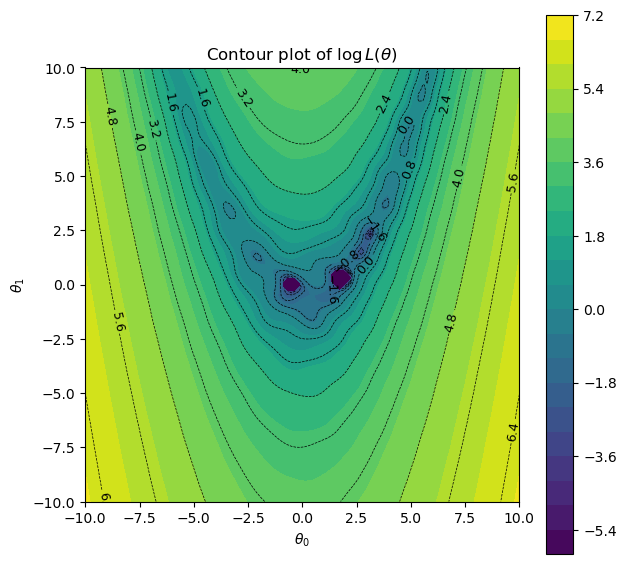

In [21]:
show_history(L_hard, history=None, correct=None, area=(-10,10))


Note that it is still a 2-dimensional function only, but the shape is visibly more challenging to optimised. 

If we just run the Gradient descent function as before, we get a very poor result:

In [22]:
theta_0 = np.array([5.0, 5.0])
delta = 0.2 # how big of steps to take
n_steps = 20
print(f"Initial loss: {L_hard(theta_0)}")

theta_20, history = gradient_descent(L_hard, theta_0, delta, n_steps)

# print your final solution (hopefully something close to the optimum)
print(f"Solution={theta_20}")

Initial loss: 3.047041912993701
Iteration 1, Loss: 1.5872919042253364
Iteration 2, Loss: 0.7176064013490981
Iteration 3, Loss: 0.6111527318224241
Iteration 4, Loss: 0.5882618513787065
Iteration 5, Loss: 0.5819549174412435
Iteration 6, Loss: 0.5797133365867703
Iteration 7, Loss: 0.5787798759249505
Iteration 8, Loss: 0.5783506254236022
Iteration 9, Loss: 0.5781398571903166
Iteration 10, Loss: 0.578031611800754
Iteration 11, Loss: 0.5779742303418245
Iteration 12, Loss: 0.577943111326487
Iteration 13, Loss: 0.577925952084068
Iteration 14, Loss: 0.5779163736874737
Iteration 15, Loss: 0.577910978043089
Iteration 16, Loss: 0.5779079178343473
Iteration 17, Loss: 0.577906173301219
Iteration 18, Loss: 0.5779051749575143
Iteration 19, Loss: 0.5779046019713447
Iteration 20, Loss: 0.5779042723890128
Solution=[4.12692268 4.59679607]


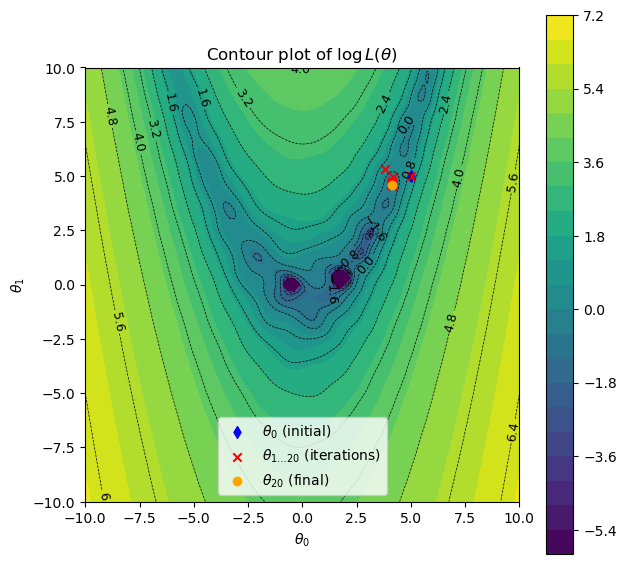

In [23]:
show_history(L_hard, history=history, correct=None, area=(-10,10))

This is clearly a complete failure!

### Task 4 - Momentum *[4 marks total: 2 visible and 2 hidden]*

In this task we will try and implement *momentum* as seen in class to improve the robustness of the optimisation. 

As a reminder, momentum helps gradient descent optimising across plateaus and in some instances even local minima by accumulating a velocity vector, which bring some consistency to the parameter updates when the gradient is unstable. 

As seen in class, the equations are as follows: 

$$ v_{t+1} = \gamma v_t + \delta \nabla L(\theta_{t}) $$

$$ \theta_{t+1} = \theta_t - v_{t+1} $$

where $\delta$ is the step size, $\gamma$ is the decay of the momentum ($\gamma=0$ is gradient descent without momentum, and for $\gamma=1$ the momentum never fades and the algorithm will not converge). 

Implement gradient descent with momentum in the function below: 

In [24]:
def gradient_descent_momentum(L, theta_0, delta, gamma, n_steps=20): 
    grad_L = grad(L)
    theta = theta_0
    history = [(0, theta, L(theta))]
    v = 0.0
    for i in range(n_steps):
        v = gamma * v + delta * grad_L(theta)
        theta = theta - v
        if not silent: 
            print(f"Iteration {i+1}, Loss: {L(theta)}")
        history.append((i+1, theta, L(theta)))
    return theta, history

The cell below will run some simple tests to check your algorithm (but they are not a guarantee of correctness!)

In [25]:

def L_test(x): 
    return np.sum(x**2)

ltg = grad(L_test)
print(ltg(np.array([0.0, 0.0])))

with tick.marks(1): 
    t1, h1 = gradient_descent_momentum(L_test, np.array([0.0,0.0]), 0.1, 0.99, 2)
    assert np.linalg.norm(t1, ord=2) < 1e-5, "ERROR the algorithm should not move if it starts at the solution"

with tick.marks(1): 
    t1, h1 = gradient_descent_momentum(L_test, np.array([1.0,1.0]), 0.1, 0.99, 2)
    assert np.linalg.norm(h1[1][1], ord=2) < np.linalg.norm(h1[0][1], ord=2), "ERROR loss should be decreasing at the first iteration"




[0. 0.]
Iteration 1, Loss: 0.0
Iteration 2, Loss: 0.0


Iteration 1, Loss: 1.2800000000000002
Iteration 2, Loss: 0.390728


Once you are convinced your code is correct, you can then run the new algorithm 
on the hard scenario and see what is happening: 

In [26]:
theta_0 = np.array([5.0, 5.0])
delta = 0.05 # how big of steps to take
gamma = 0.99
n_steps = 20
print(f"Initial loss: {L_hard(theta_0)}")

theta_20_m, history_m = gradient_descent_momentum(L_hard, theta_0, delta, gamma, n_steps)

# print your final solution (hopefully something close to the optimum)
print(f"Solution={theta_20}")


Initial loss: 3.047041912993701
Iteration 1, Loss: 1.6337365203281362
Iteration 2, Loss: 0.9697370643745234
Iteration 3, Loss: 1.40735408918263
Iteration 4, Loss: 2.3787702703524687
Iteration 5, Loss: 2.895081224956795
Iteration 6, Loss: 2.404128085286068
Iteration 7, Loss: 1.359673031960075
Iteration 8, Loss: 0.6068230043109542
Iteration 9, Loss: 1.2022630437939599
Iteration 10, Loss: 2.6775594612244755
Iteration 11, Loss: 2.3043179658809017
Iteration 12, Loss: 0.6833910851239636
Iteration 13, Loss: 0.5190075118185
Iteration 14, Loss: 1.3614712846012493
Iteration 15, Loss: 2.01065537533426
Iteration 16, Loss: 2.14218021952717
Iteration 17, Loss: 1.7575810105593128
Iteration 18, Loss: 1.242369324137435
Iteration 19, Loss: 0.7976327037103764
Iteration 20, Loss: 0.24927412467820542
Solution=[4.12692268 4.59679607]


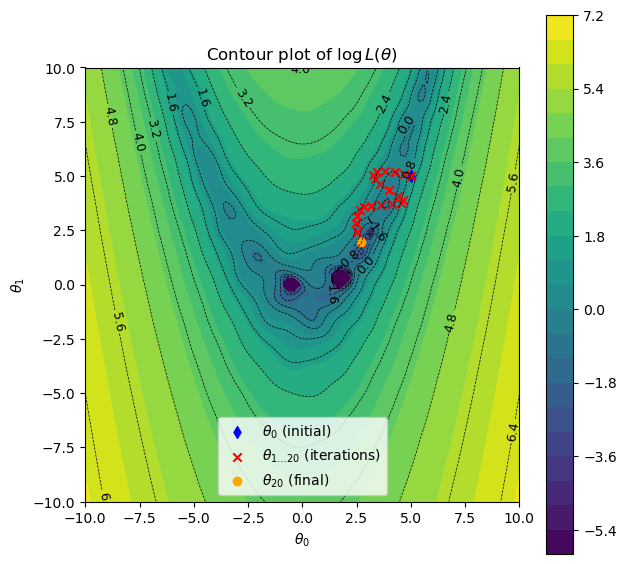

In [27]:
show_history(L_hard, history=history_m, correct=None, area=(-10,10))

In [28]:
# This cell will run some hidden tests on your code, to check it works as intended. 


### Task 5 - Random Restart *[2 marks all visible]*

It is obvious that this function has many local minima, unlike the first one. In this case, it is visible because it is a function of only two variables, but in most cases you will be optimising functions of many more dimensions and will not be able to visualise it. 

Another approach seen in class to deal with this issue is *random restart*, in other words, starting your algorithm multiple times, to find different local minima and selecting the best one. 

Implement a random restart approach for your algorithm, taking inspiration from the algorithms written before. 
For `n_runs` times, do the following: 
- Use the Numpy function `np.random.uniform(min_val, max_val, shape)` to generate a random $\theta_0$
- Run the gradient descent with momentum and the same hyperparameters every time
Return the best solution as `theta` and the histories from all runs in `history_list`







In [29]:
def random_restart(L, delta, gamma, n_steps=20, n_runs=5): 
    best_l = None
    history_list = []
    for r in range(n_runs):
        theta_0 = np.random.uniform(-10, 10, 2)
        t, h = gradient_descent_momentum(L, theta_0, delta, gamma, n_steps)
        history_list.append(h)
        if best_l is None or L(t) < best_l:
            best_l = L(t)
            theta = t
    return theta, history_list
    

In [30]:

theta, h_list = random_restart(L, delta, gamma, n_steps=10, n_runs=10)

with tick.marks(2): 
    assert len(h_list) == 10, "ERROR: History list is not of the correct length"
    assert min([h[-1][2] for h in h_list]) == L(theta), "ERROR: theta is not the best solution"

Iteration 1, Loss: 64.85902397800902
Iteration 2, Loss: 40.478516864675434
Iteration 3, Loss: 16.41644226405451
Iteration 4, Loss: 1.8471590645376854
Iteration 5, Loss: 2.0808072415054646
Iteration 6, Loss: 16.579855964323755
Iteration 7, Loss: 39.28401882413387
Iteration 8, Loss: 61.071532566796016
Iteration 9, Loss: 73.35930954731326
Iteration 10, Loss: 71.42244116483909
Iteration 1, Loss: 27.78727823473775
Iteration 2, Loss: 17.342040346299832
Iteration 3, Loss: 7.03322715695596
Iteration 4, Loss: 0.7913705714648069
Iteration 5, Loss: 0.8914714749974301
Iteration 6, Loss: 7.10323779970459
Iteration 7, Loss: 16.830286586104
Iteration 8, Loss: 26.164619255306615
Iteration 9, Loss: 31.42901974890343
Iteration 10, Loss: 30.599215392517735
Iteration 1, Loss: 59.4854203439966
Iteration 2, Loss: 37.124850836688275
Iteration 3, Loss: 15.056331543955043
Iteration 4, Loss: 1.694120982047203
Iteration 5, Loss: 1.9084112868820302
Iteration 6, Loss: 15.206206334759482
Iteration 7, Loss: 36.02931

### Task 6 - Tuning the Hyperparameters *[4 marks, all hidden]*

Finally, in this task, we will put it together to try and get the most robust optimisation: You can now tune the two parameters $\delta$ (`delta`) and $\gamma$ (`gamma`) to get the best performance. 
- set the step size $\delta$, remember that a small value will lead to slow convergence, but a large one may lead to divergence
- set the decay of the momentum $\gamma$. Remember that $\gamma=0$ means no momentum, but $\gamma=1$ would never converge to a solution.
- also experiment with different seeds to see if your settings work reliably across seeds. 

In [37]:
# vary the seed too to check that 
np.random.seed(100)

delta = 0.02
gamma = 0.8




Then you can run the cell below to start the optimisation for the parameters chosen above. 

- Verify that your chosen parameters work well across multiple seeds and not just 42!
- There is no visible test for this task, but you can verify visually how good your solutions are. 

Best loss is -0.2873191770377494


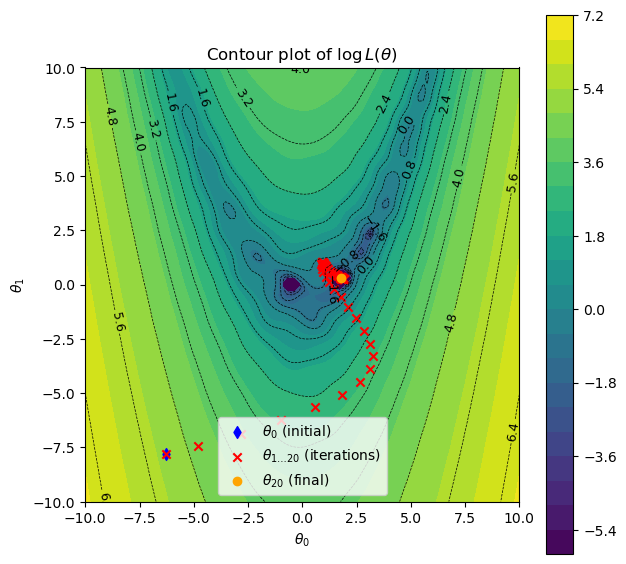

In [38]:
silent = True # this will reduce the output
theta, h_list = random_restart(L_hard, delta, gamma, n_steps=100, n_runs=10)
print(f'Best loss is {L_hard(theta)}')

best = np.argmin([h[-1][2] for h in h_list])

show_history(L_hard, history=h_list[best], correct=None, area=(-10,10))

In [33]:
# This cell will run some hidden tests to check how good are your choice of parameters. 
# the best is the solution you found, the more points you get. 



---
## Before you finish

1. **Kernel &rarr; Restart Kernel and Run All Cells.** The notebook must run top to bottom with no errors (no red boxes, no tracebacks).
2. Check the **marks summary** below.
3. Upload the completed `.ipynb` to Moodle. 



# Appendix: Marks summary

Run **Kernel &rarr; Restart Kernel and Run All Cells** before reading this, or it will be out of date.


In [34]:
print("Marks available: 20  (visible with feedback: 11,  hidden: 9)")

# tick.summarise_marks() only reads the id-based tick.Marks() records, which this
# lab does not use; summarise from the counters tick.marks() maintains instead.
import IPython.display
if tick.available_marks > 0:
    IPython.display.display(IPython.display.HTML(
        """<!--{id:"TOTALMARK",marks:"%d", available:"%d"}  -->
        <div class="alert alert-box alert-success">
        <h1> Marks in this run: %d/%d (%.1f%%) </h1> </div>"""
        % (tick.total_marks, tick.available_marks,
           tick.total_marks, tick.available_marks,
           tick.total_marks / tick.available_marks * 100)))
else:
    print("No marks recorded -- use Kernel -> Restart Kernel and Run All Cells.")


Marks available: 20  (visible with feedback: 11,  hidden: 9)
